In [1]:
%pip install pandas sqlalchemy psycopg2-binary python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# Find the project root containing .env
current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if (p / ".env").is_file()),
    None)
if project_root is None:
    raise FileNotFoundError(
        "Could not find .env. Open Jupyter from your project "
        "or update the .env path below.")
load_dotenv(project_root / ".env", override=False)
# Read database settings
database_url = os.getenv("DATABASE_URL")
if database_url:
    engine = create_engine(database_url, pool_pre_ping=True)
else:
    # Adjust these names if your .env uses different variable names.
    db_name = os.getenv("DB_NAME") or os.getenv("DB_DATABASE")
    db_user = os.getenv("DB_USER") or os.getenv("DB_USERNAME")
    db_password = os.getenv("DB_PASSWORD") or os.getenv("DB_PASS")
    db_host = os.getenv("DB_HOST", "localhost")
    db_port = os.getenv("DB_PORT", "5432")
    if not all([db_name, db_user, db_password]):
        raise ValueError(
            "Database settings missing. Check the variable names "
            "in your project's .env file.")
    db_url = URL.create(
        drivername="postgresql+psycopg2",
        username=db_user,
        password=db_password,
        host=db_host,
        port=int(db_port),
        database=db_name)
    engine = create_engine(db_url, pool_pre_ping=True)
# Test connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database(), version()"))
    database, version = result.fetchone()
print("PostgreSQL connected successfully!")
print("Database:", database)
print("Connection is ready for SmartSpend AI.")

PostgreSQL connected successfully!
Database: smart spend ai
Connection is ready for SmartSpend AI.


In [3]:
# ==========================================
# 1. General Utilities
# ==========================================
import os
import warnings
from pathlib import Path
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")
# ==========================================
# 2. Data Manipulation
# ==========================================
import pandas as pd
import numpy as np
# ==========================================
# 3. Data Visualization
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
# ==========================================
# 4. Database Connection
# ==========================================
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# ==========================================
# 5. Data Preprocessing
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# ==========================================
# 6. Machine Learning - Regression
# ==========================================
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    IsolationForest
)
# ==========================================
# 7. Machine Learning - Classification
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
# ==========================================
# 8. Model Evaluation
# ==========================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score)
# ==========================================
# 9. Anomaly Detection and Clustering
# ==========================================
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
# ==========================================
# 10. Model Saving and Loading
# ==========================================
import joblib
# ==========================================
# 11. FastAPI - Later, for API integration
# ==========================================
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
print("All SmartSpend AI libraries imported successfully!")

All SmartSpend AI libraries imported successfully!


In [4]:
with engine.connect() as connection:
    transactions_df = pd.read_sql(
        text("SELECT * FROM transactions"),
        connection)
    categories_df = pd.read_sql(
        text("SELECT * FROM categories"),
        connection)
    budgets_df = pd.read_sql(
        text("SELECT * FROM budgets"),
        connection)
    users_df = pd.read_sql(
        text("SELECT * FROM users"),
        connection)
    accounts_df = pd.read_sql(
        text("SELECT * FROM accounts"),
        connection)
print("Transactions:", transactions_df.shape)
print("Categories:", categories_df.shape)
print("budgets:", categories_df.shape)
print("users:", categories_df.shape)
print("accounts:", categories_df.shape)

Transactions: (265, 12)
Categories: (14, 8)
budgets: (14, 8)
users: (14, 8)
accounts: (14, 8)


In [5]:
transactions_df.head()

,id,user_id,account_id,category_id,amount,transaction_type,merchant,description,transaction_date,source,created_at,updated_at
0,1,1,1,1,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00,manual,2026-10-12 04:40:14.288000+00:00,2026-10-12 04:40:14.302000+00:00
1,3,2,2,2,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.937000+00:00,2026-10-12 05:48:48.937000+00:00
2,4,2,2,2,500.0,income,Demo Scholarship,Sample scholarship received,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.939000+00:00,2026-10-12 05:48:48.939000+00:00
3,2,2,2,2,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.931000+00:00,2026-10-12 05:48:48.952000+00:00
4,6,3,3,3,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00,manual,2026-10-12 15:24:26.438000+00:00,2026-10-12 15:24:26.438000+00:00


In [6]:
categories_df.head()

,id,user_id,name,type,icon,is_system,created_at,updated_at
0,1,1.0,Demo Food,expense,utensils,False,2026-10-12 04:40:14.282000+00:00,2026-10-12 04:40:14.282000+00:00
1,2,2.0,Demo Food,expense,utensils,False,2026-10-12 05:48:48.925000+00:00,2026-10-12 05:48:48.925000+00:00
2,3,3.0,Demo Food,expense,utensils,False,2026-10-12 15:24:26.431000+00:00,2026-10-12 15:24:26.431000+00:00
3,4,NaN,Salary,income,wallet,True,2026-10-26 04:58:15.582000+00:00,2026-10-26 04:58:15.582000+00:00
4,5,NaN,Freelance,income,laptop,True,2026-10-26 04:58:15.589000+00:00,2026-10-26 04:58:15.589000+00:00


In [7]:
users_df.head()

,id,first_name,last_name,email,password_hash,currency,created_at,updated_at
0,1,Demo,User,demo_1791780014264@example.com,DEMO_HASH_NOT_FOR_LOGIN,INR,2026-10-12 04:40:14.265000+00:00,2026-10-12 04:40:14.265000+00:00
1,2,Demo,User,demo_1791784128906@example.com,DEMO_HASH_NOT_FOR_LOGIN,INR,2026-10-12 05:48:48.908000+00:00,2026-10-12 05:48:48.908000+00:00
2,3,Demo,User,demo_1791818666413@example.com,DEMO_HASH_NOT_FOR_LOGIN,INR,2026-10-12 15:24:26.414000+00:00,2026-10-12 15:24:26.414000+00:00
3,4,Aarav,Demo,aarav.demo@smartspend.test,DEMO_ONLY_NOT_A_REAL_PASSWORD_HASH,INR,2026-10-26 04:58:15.464000+00:00,2026-10-26 04:58:15.464000+00:00
4,5,Meera,Demo,meera.demo@smartspend.test,DEMO_ONLY_NOT_A_REAL_PASSWORD_HASH,INR,2026-10-26 04:58:15.524000+00:00,2026-10-26 04:58:15.524000+00:00


In [8]:
accounts_df.head()

,id,user_id,account_name,account_type,institution_name,currency,is_active,created_at,updated_at
0,1,1,Demo Cash Wallet,cash,NaN,INR,True,2026-10-12 04:40:14.278000+00:00,2026-10-12 04:40:14.278000+00:00
1,2,2,Demo Cash Wallet,cash,NaN,INR,True,2026-10-12 05:48:48.921000+00:00,2026-10-12 05:48:48.921000+00:00
2,3,3,Demo Cash Wallet,cash,NaN,INR,True,2026-10-12 15:24:26.426000+00:00,2026-10-12 15:24:26.426000+00:00
3,4,4,Demo Bank Account,bank,Demo Bank,INR,True,2026-10-26 04:58:15.544000+00:00,2026-10-26 04:58:15.544000+00:00
4,5,4,Demo Wallet,wallet,Demo Wallet,INR,True,2026-10-26 04:58:15.555000+00:00,2026-10-26 04:58:15.555000+00:00


In [9]:
budgets_df.head()

,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at
0,1,4,6,3000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:16.996000+00:00,2026-10-26 04:58:16.996000+00:00
1,2,4,7,2000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.006000+00:00,2026-10-26 04:58:17.006000+00:00
2,3,4,8,1200.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.011000+00:00,2026-10-26 04:58:17.011000+00:00
3,4,4,10,1500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.018000+00:00,2026-10-26 04:58:17.018000+00:00
4,5,5,6,3500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.026000+00:00,2026-10-26 04:58:17.026000+00:00


In [10]:
transactions_df.columns

Index(['id', 'user_id', 'account_id', 'category_id', 'amount',
       'transaction_type', 'merchant', 'description', 'transaction_date',
       'source', 'created_at', 'updated_at'],
      dtype='str')

In [11]:
budgets_df.columns

Index(['id', 'user_id', 'category_id', 'amount_limit', 'period', 'start_date',
       'end_date', 'created_at', 'updated_at'],
      dtype='str')

In [12]:
users_df.columns

Index(['id', 'first_name', 'last_name', 'email', 'password_hash', 'currency',
       'created_at', 'updated_at'],
      dtype='str')

In [13]:
accounts_df.columns

Index(['id', 'user_id', 'account_name', 'account_type', 'institution_name',
       'currency', 'is_active', 'created_at', 'updated_at'],
      dtype='str')

In [14]:
categories_df.columns

Index(['id', 'user_id', 'name', 'type', 'icon', 'is_system', 'created_at',
       'updated_at'],
      dtype='str')

In [15]:
# Check whether IDs are unique in each table
print("Transactions: unique IDs =", transactions_df["id"].nunique())
print("Categories: unique IDs =", categories_df["id"].nunique())
print("Accounts: unique IDs =", accounts_df["id"].nunique())
print("Users: unique IDs =", users_df["id"].nunique())
print("Budgets: unique IDs =", budgets_df["id"].nunique())


Transactions: unique IDs = 265
Categories: unique IDs = 14
Accounts: unique IDs = 8
Users: unique IDs = 7
Budgets: unique IDs = 8


In [16]:
# Check transaction foreign-key relationships
checks = {
    "user_id": users_df["id"],
    "account_id": accounts_df["id"],
    "category_id": categories_df["id"]
}
for column, valid_ids in checks.items():
    missing_links = ~transactions_df[column].isin(valid_ids)
    print(
        f"{column}: "
        f"{missing_links.sum()} transactions have no matching record"
    )

user_id: 0 transactions have no matching record
account_id: 0 transactions have no matching record
category_id: 0 transactions have no matching record


In [17]:
query = text("""
    SELECT
        t.id AS transaction_id,
        t.user_id,
        u.first_name,
        u.last_name,
        t.account_id,
        a.account_name,
        t.category_id,
        c.name AS category_name,
        c.type AS category_type,
        t.amount,
        t.transaction_type,
        t.merchant,
        t.description,
        t.transaction_date
    FROM transactions AS t
    LEFT JOIN users AS u
        ON t.user_id = u.id
    LEFT JOIN accounts AS a
        ON t.account_id = a.id
    LEFT JOIN categories AS c
        ON t.category_id = c.id
    ORDER BY t.transaction_date DESC;
""")
with engine.connect() as connection:
    transactions_eda_df = pd.read_sql(query, connection)
print("Joined dataset shape:", transactions_eda_df.shape)
display(transactions_eda_df.head(10))

Joined dataset shape: (265, 14)


,transaction_id,user_id,first_name,last_name,account_id,account_name,category_id,category_name,category_type,amount,transaction_type,merchant,description,transaction_date
0,1,1,Demo,User,1,Demo Cash Wallet,1,Demo Food,expense,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00
1,3,2,Demo,User,2,Demo Cash Wallet,2,Demo Food,expense,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00
2,4,2,Demo,User,2,Demo Cash Wallet,2,Demo Food,expense,500.0,income,Demo Scholarship,Sample scholarship received,2026-10-12 00:00:00+00:00
3,2,2,Demo,User,2,Demo Cash Wallet,2,Demo Food,expense,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00
4,6,3,Demo,User,3,Demo Cash Wallet,3,Demo Food,expense,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00
5,7,3,Demo,User,3,Demo Cash Wallet,3,Demo Food,expense,500.0,income,Demo Scholarship,Sample scholarship received,2026-10-12 00:00:00+00:00
6,5,3,Demo,User,3,Demo Cash Wallet,3,Demo Food,expense,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00
7,256,7,Sana,Demo,8,Demo Bank Account,5,Freelance,income,1000.0,income,Demo Freelance Client,Demo freelance income 2026-06,2026-06-15 12:00:00+00:00
8,190,6,Ishan,Demo,7,Demo Bank Account,5,Freelance,income,2500.0,income,Demo Freelance Client,Demo freelance income 2026-06,2026-06-15 12:00:00+00:00
9,64,4,Aarav,Demo,4,Demo Bank Account,5,Freelance,income,1500.0,income,Demo Freelance Client,Demo freelance income 2026-06,2026-06-15 12:00:00+00:00


In [18]:
display(accounts_df[["id", "user_id", "account_name", "account_type"]].sort_values("id"))

,id,user_id,account_name,account_type
0,1,1,Demo Cash Wallet,cash
1,2,2,Demo Cash Wallet,cash
2,3,3,Demo Cash Wallet,cash
3,4,4,Demo Bank Account,bank
4,5,4,Demo Wallet,wallet
5,6,5,Demo Bank Account,bank
6,7,6,Demo Bank Account,bank
7,8,7,Demo Bank Account,bank


In [19]:
display(categories_df[["id", "user_id", "name", "type", "is_system"]].sort_values("id"))

,id,user_id,name,type,is_system
0,1,1.0,Demo Food,expense,False
1,2,2.0,Demo Food,expense,False
2,3,3.0,Demo Food,expense,False
3,4,NaN,Salary,income,True
4,5,NaN,Freelance,income,True
5,6,NaN,Groceries,expense,True
6,7,NaN,Food & Dining,expense,True
7,8,NaN,Transport,expense,True
8,9,NaN,Bills & Utilities,expense,True
9,10,NaN,Shopping,expense,True


In [20]:
display(users_df[["id", "first_name", "last_name", "currency"]])

,id,first_name,last_name,currency
0,1,Demo,User,INR
1,2,Demo,User,INR
2,3,Demo,User,INR
3,4,Aarav,Demo,INR
4,5,Meera,Demo,INR
5,6,Ishan,Demo,INR
6,7,Sana,Demo,INR


In [21]:
# Check transaction-user-account-category ownership
check_df = (
    transactions_df
    .merge(
        accounts_df[["id", "user_id"]],
        left_on="account_id",
        right_on="id",
        how="left",
        suffixes=("", "_account"))
    .rename(columns={"user_id_account": "account_user_id"})
    .merge(
        categories_df[["id", "user_id", "is_system"]],
        left_on="category_id",
        right_on="id",
        how="left",
        suffixes=("", "_category"))
    .rename(columns={"user_id_category": "category_user_id"}))
print(
    "Transactions whose account belongs to a different user:",
    (check_df["user_id"] != check_df["account_user_id"]).sum())
category_owner_mismatch = (
    check_df["category_user_id"].notna()
    & (check_df["user_id"] != check_df["category_user_id"]))
print(
    "Transactions with a category belonging to a different user:",
    category_owner_mismatch.sum())

Transactions whose account belongs to a different user: 0
Transactions with a category belonging to a different user: 0


In [22]:
# 1. Dataset size
print("Total transactions:", len(transactions_df))

# 2. Missing values
print("\nMissing values:")
display(transactions_df.isnull().sum())

# 3. Exact duplicate rows
print("\nDuplicate transaction rows:",
      transactions_df.duplicated().sum())

# 4. Duplicate transaction IDs
print("Duplicate transaction IDs:",
      transactions_df["id"].duplicated().sum())

# 5. Transaction types
print("\nTransaction types:")
display(transactions_df["transaction_type"].value_counts())

# 6. Transaction date range
print("\nEarliest transaction:",
      transactions_df["transaction_date"].min())

print("Latest transaction:",
      transactions_df["transaction_date"].max())

# 7. Amount summary
print("\nTransaction amount summary:")
display(transactions_df["amount"].describe())

Total transactions: 265

Missing values:


id                  0
user_id             0
account_id          0
category_id         0
amount              0
transaction_type    0
merchant            0
description         0
transaction_date    0
source              0
created_at          0
updated_at          0
dtype: int64


Duplicate transaction rows: 0
Duplicate transaction IDs: 0

Transaction types:


transaction_type
expense    221
income      44
Name: count, dtype: int64


Earliest transaction: 2026-01-01 12:00:00+00:00
Latest transaction: 2026-10-12 00:00:00+00:00

Transaction amount summary:


count      265.000000
mean      4108.830189
std       7474.855613
min        120.000000
25%        900.000000
50%       1300.000000
75%       2400.000000
max      32000.000000
Name: amount, dtype: float64

In [23]:
# Separate income and expenses
income_df = transactions_df[
    transactions_df["transaction_type"] == "income"]
expense_df = transactions_df[
    transactions_df["transaction_type"] == "expense"]
# Calculate financial totals
total_income = income_df["amount"].sum()
total_expenses = expense_df["amount"].sum()
net_cash_flow = total_income - total_expenses
print(f"Total income:   ₹{total_income:,.2f}")
print(f"Total expenses: ₹{total_expenses:,.2f}")
print(f"Net cash flow:  ₹{net_cash_flow:,.2f}")
print(f"\nNumber of income transactions: {len(income_df)}")
print(f"Number of expense transactions: {len(expense_df)}")

Total income:   ₹673,000.00
Total expenses: ₹415,840.00
Net cash flow:  ₹257,160.00

Number of income transactions: 44
Number of expense transactions: 221


In [24]:
# Cash-flow surplus as a percentage of income
if total_income > 0:
    surplus_percentage = (
        net_cash_flow / total_income) * 100
else:
    surplus_percentage = 0
print(f"Net cash flow: ₹{net_cash_flow:,.2f}")
print(f"Cash-flow surplus percentage: {surplus_percentage:.2f}%")

Net cash flow: ₹257,160.00
Cash-flow surplus percentage: 38.21%


In [25]:
# Calculate income, expenses and net cash flow for each user
user_finances = (
    transactions_df
    .pivot_table(
        index="user_id",
        columns="transaction_type",
        values="amount",
        aggfunc="sum",
        fill_value=0)
    .reset_index())
# Ensure both columns exist
for col in ["income", "expense"]:
    if col not in user_finances.columns:
        user_finances[col] = 0
user_finances["net_cash_flow"] = (
    user_finances["income"] - user_finances["expense"])
user_finances["surplus_percentage"] = (
    user_finances["net_cash_flow"]
    / user_finances["income"].replace(0, float("nan"))) * 100
display(user_finances)

transaction_type,user_id,expense,income,net_cash_flow,surplus_percentage
0,1,250.0,0.0,-250.0,NaN
1,2,370.0,500.0,130.0,26.000000
2,3,370.0,500.0,130.0,26.000000
3,4,96600.0,159000.0,62400.0,39.245283
4,5,128700.0,192000.0,63300.0,32.968750
5,6,83050.0,147000.0,63950.0,43.503401
6,7,106500.0,174000.0,67500.0,38.793103


In [26]:
# Join transaction data with related tables
transactions_eda_df = (
    transactions_df
    .merge(
        users_df[["id", "first_name", "last_name"]],
        left_on="user_id",
        right_on="id",
        how="left",
        suffixes=("", "_user"))
    .drop(columns=["id_user"])
    .merge(
        accounts_df[["id", "account_name", "account_type"]],
        left_on="account_id",
        right_on="id",
        how="left",
        suffixes=("", "_account"))
    .drop(columns=["id_account"])
    .merge(
        categories_df[["id", "name", "type", "is_system"]],
        left_on="category_id",
        right_on="id",
        how="left",
        suffixes=("", "_category"))
    .drop(columns=["id_category"])
    .rename(columns={
        "name": "category_name",
        "type": "category_type"}))
print("Joined dataset shape:", transactions_eda_df.shape)
display(transactions_eda_df.head())

Joined dataset shape: (265, 19)


,id,user_id,account_id,category_id,amount,transaction_type,merchant,description,transaction_date,source,created_at,updated_at,first_name,last_name,account_name,account_type,category_name,category_type,is_system
0,1,1,1,1,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00,manual,2026-10-12 04:40:14.288000+00:00,2026-10-12 04:40:14.302000+00:00,Demo,User,Demo Cash Wallet,cash,Demo Food,expense,False
1,3,2,2,2,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.937000+00:00,2026-10-12 05:48:48.937000+00:00,Demo,User,Demo Cash Wallet,cash,Demo Food,expense,False
2,4,2,2,2,500.0,income,Demo Scholarship,Sample scholarship received,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.939000+00:00,2026-10-12 05:48:48.939000+00:00,Demo,User,Demo Cash Wallet,cash,Demo Food,expense,False
3,2,2,2,2,250.0,expense,Demo Cafe,Updated sample lunch expense,2026-10-12 00:00:00+00:00,manual,2026-10-12 05:48:48.931000+00:00,2026-10-12 05:48:48.952000+00:00,Demo,User,Demo Cash Wallet,cash,Demo Food,expense,False
4,6,3,3,3,120.0,expense,Demo Grocery Store,Sample grocery shopping,2026-10-12 00:00:00+00:00,manual,2026-10-12 15:24:26.438000+00:00,2026-10-12 15:24:26.438000+00:00,Demo,User,Demo Cash Wallet,cash,Demo Food,expense,False


In [27]:
transactions_eda_df["transaction_date"] = pd.to_datetime(
    transactions_eda_df["transaction_date"],
    errors="coerce",
    utc=True)
print("Invalid transaction dates:",
      transactions_eda_df["transaction_date"].isna().sum())
print("Date range:",
      transactions_eda_df["transaction_date"].min(),
      "to",
      transactions_eda_df["transaction_date"].max())

Invalid transaction dates: 0
Date range: 2026-01-01 12:00:00+00:00 to 2026-10-12 00:00:00+00:00


In [28]:
user_finances = (
    transactions_eda_df
    .pivot_table(
        index=["user_id", "first_name", "last_name"],
        columns="transaction_type",
        values="amount",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index())
for col in ["income", "expense"]:
    if col not in user_finances.columns:
        user_finances[col] = 0
user_finances["net_cash_flow"] = (
    user_finances["income"] - user_finances["expense"])
user_finances["surplus_percentage"] = np.where(
    user_finances["income"] > 0,
    user_finances["net_cash_flow"]
    / user_finances["income"] * 100,
    np.nan)
display(user_finances)

transaction_type,user_id,first_name,last_name,expense,income,net_cash_flow,surplus_percentage
0,1,Demo,User,250.0,0.0,-250.0,NaN
1,2,Demo,User,370.0,500.0,130.0,26.000000
2,3,Demo,User,370.0,500.0,130.0,26.000000
3,4,Aarav,Demo,96600.0,159000.0,62400.0,39.245283
4,5,Meera,Demo,128700.0,192000.0,63300.0,32.968750
5,6,Ishan,Demo,83050.0,147000.0,63950.0,43.503401
6,7,Sana,Demo,106500.0,174000.0,67500.0,38.793103


In [29]:
expense_data = transactions_eda_df[
    transactions_eda_df["transaction_type"] == "expense"].copy()
category_expenses = (
    expense_data
    .groupby("category_name", dropna=False)["amount"]
    .agg(["sum", "count", "mean"])
    .reset_index()
    .sort_values("sum", ascending=False))
category_expenses.columns = [
    "category",
    "total_expenses",
    "transaction_count",
    "average_expense"]
display(category_expenses)

,category,total_expenses,transaction_count,average_expense
7,Rent,171000.0,24,7125.000000
5,Groceries,62050.0,24,2585.416667
4,Food & Dining,37200.0,24,1550.000000
0,Bills & Utilities,33000.0,24,1375.000000
8,Shopping,32400.0,24,1350.000000
2,Education,27000.0,24,1125.000000
9,Transport,24600.0,24,1025.000000
3,Entertainment,16200.0,24,675.000000
6,Health,11400.0,24,475.000000
1,Demo Food,990.0,5,198.000000


In [30]:
transactions_eda_df["month"] = (
    transactions_eda_df["transaction_date"]
    .dt.to_period("M")
    .astype(str))
monthly_summary = (
    transactions_eda_df
    .pivot_table(
        index="month",
        columns="transaction_type",
        values="amount",
        aggfunc="sum",
        fill_value=0).reset_index())
for col in ["income", "expense"]:
    if col not in monthly_summary.columns:
        monthly_summary[col] = 0
monthly_summary["net_cash_flow"] = (
    monthly_summary["income"] - monthly_summary["expense"])
display(monthly_summary)

transaction_type,month,expense,income,net_cash_flow
0,2026-01,67950.0,112000.0,44050.0
1,2026-02,68400.0,112000.0,43600.0
2,2026-03,68600.0,112000.0,43400.0
3,2026-04,68500.0,112000.0,43500.0
4,2026-05,68750.0,112000.0,43250.0
5,2026-06,72650.0,112000.0,39350.0
6,2026-10,990.0,1000.0,10.0


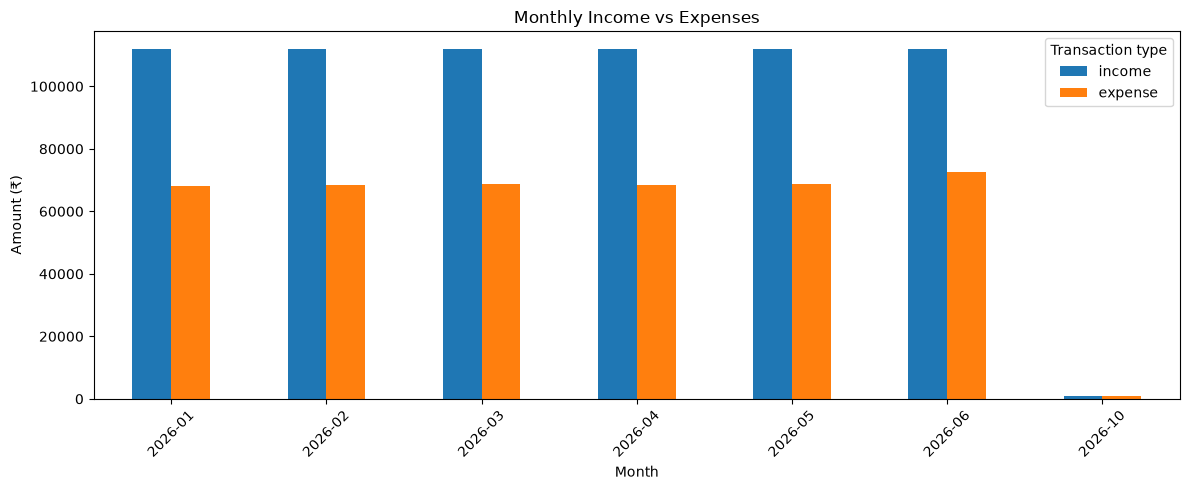

In [31]:
monthly_plot = monthly_summary.set_index("month")[
    ["income", "expense"]]
monthly_plot.plot(kind="bar", figsize=(12, 5))
plt.title("Monthly Income vs Expenses")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.legend(title="Transaction type")
plt.tight_layout()
plt.show()

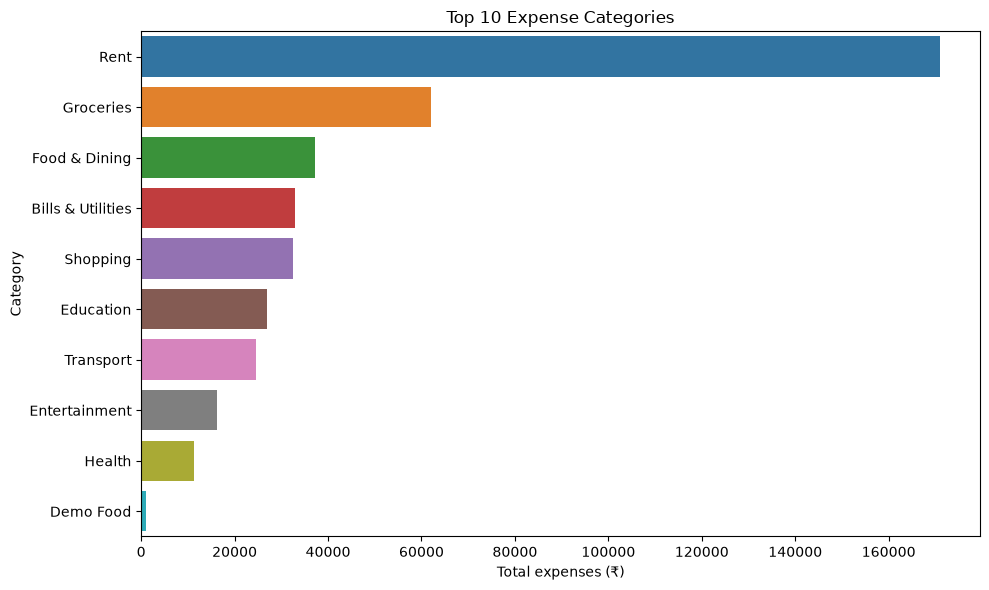

In [32]:
top_categories = category_expenses.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_categories,
    x="total_expenses",
    y="category",
    hue="category",
    legend=False)
plt.title("Top 10 Expense Categories")
plt.xlabel("Total expenses (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [33]:
expense_data = expense_data.sort_values(
    "amount",
    ascending=False)
display(
    expense_data[
        [
            "user_id",
            "first_name",
            "category_name",
            "amount",
            "merchant",
            "description",
            "transaction_date"]].head(15))

,user_id,first_name,category_name,amount,merchant,description,transaction_date
92,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-02,2026-02-10 12:00:00+00:00
102,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-03,2026-03-10 12:00:00+00:00
82,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-01,2026-01-10 12:00:00+00:00
122,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-05,2026-05-10 12:00:00+00:00
112,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-04,2026-04-10 12:00:00+00:00
132,5,Meera,Rent,9000.0,Demo rent,Demo rent expense 2026-06,2026-06-10 12:00:00+00:00
220,7,Sana,Rent,7500.0,Demo rent,Demo rent expense 2026-02,2026-02-10 12:00:00+00:00
242,7,Sana,Rent,7500.0,Demo rent,Demo rent expense 2026-04,2026-04-10 12:00:00+00:00
231,7,Sana,Rent,7500.0,Demo rent,Demo rent expense 2026-03,2026-03-10 12:00:00+00:00
253,7,Sana,Rent,7500.0,Demo rent,Demo rent expense 2026-05,2026-05-10 12:00:00+00:00
